# **Entrega 2: Análisis Exploratorio - Predicción de Tsunamis**


> **Versión corregida tras la devolución de la Entrega 2.** Cambios respecto de la versión presentada:
>
> - **Los títulos de las hipótesis ya no dan la respuesta.** Ahora cada título es la pregunta que se pone a prueba. La conclusión aparece recién en «Qué encontré», después de la medición.
> - **Las celdas de código sólo miden.** Antes imprimían la conclusión y la decisión («Refutada», «Entra al modelo») junto con el cálculo; ahora eso está en el texto, después del resultado.
> - **H1:** se quitó «el semáforo marca el poder predictivo», que contradecía su propio resultado (zona roja).
> - **H4:** la separación al filtrar el mar **sube** de 0,17 a 0,42; antes decía que «colapsa». La forma de usar la columna (continua o binaria) queda para medirla en el modelado.
> - **Tabla de columnas:** se corrigieron las zonas (`depth` y `dist_costa_km` son rojas, `sig` es verde) y se agregaron `nst` y `dmin`, que faltaban.
>
> Los números y gráficos son los de la versión presentada; no se recalculó nada.

> **Versión 2 (Entrega2_v2).** Se agregan dos análisis pedidos:
>
> - **Histogramas** de las columnas numéricas con cola larga (sección 1, después de la asimetría): muestran dónde está la cola y si `log1p` la corrige.
> - **Matriz de correlación** entre las columnas numéricas (nueva sección 4): busca columnas candidatas redundantes entre sí y relaciones sospechosas con el objetivo.
>
> La tabla de columnas (ahora sección 5) suma lo que salió de esos dos análisis. También se corrigió el número de filas en el texto del perfil (13.602, no 13.912).

## **1. El perfil del dataset**
En esta sección calculamos los números exactos requeridos para describir el estado inicial de nuestros datos antes de tomar decisiones de modelado.

In [1]:
# CARGA DE DATOS Y PERFIL DEL DATASET

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Carga de datos
df = pd.read_csv('https://drive.google.com/uc?export=download&id=1jaFSopVyLI6yGXoCvl6VGa5r8qO9aDFf')

**Tamaño y tipos:**

In [2]:
print("=== 1. TAMAÑO ===")
print(f"Shape: {df.shape}")
print("Cada fila representa un evento sísmico único registrado por USGS con magnitud > 5.\n")
display(df.head())

=== 1. TAMAÑO ===
Shape: (13602, 18)
Cada fila representa un evento sísmico único registrado por USGS con magnitud > 5.



,id,time,mag,magType,place,latitude,longitude,depth,tsunami,type,status,sig,gap,dmin,nst,rms,net,dist_costa_km
0,us6000th3m,2026-07-30 21:53:27.234000+00:00,5.1,mb,"62 km E of Petropavlovsk-Kamchatsky, Russia",53.0248,159.5532,72.408,0,earthquake,reviewed,400,96.0,0.546,112.0,0.65,us,23.77
1,us6000th30,2026-07-30 20:26:32.064000+00:00,5.0,mb,Kermadec Islands region,-28.4937,-176.4902,10.000,0,earthquake,reviewed,385,111.0,1.467,52.0,0.73,us,798.99
2,us6000th1t,2026-07-30 18:20:32.621000+00:00,5.0,mww,"88 km SW of Puerto Madero, Mexico",14.2669,-93.0973,8.468,0,earthquake,reviewed,385,92.0,2.207,126.0,0.79,us,88.16
3,us6000th1h,2026-07-30 17:55:58.902000+00:00,5.9,mww,"244 km NNE of Colonia, Micronesia",11.5402,139.0293,29.875,0,earthquake,reviewed,536,19.0,5.947,149.0,0.76,us,235.30
4,us6000th1b,2026-07-30 17:48:09.051000+00:00,5.1,mb,Kermadec Islands region,-31.4941,-177.6574,10.000,0,earthquake,reviewed,400,166.0,2.254,34.0,0.78,us,771.16


**Tipo de datos:**

In [3]:
print("=== 2. TIPOS DE DATOS ===")
print(df.dtypes.value_counts())
df.info()
print("\n")

=== 2. TIPOS DE DATOS ===
float64    9
object     7
int64      2
Name: count, dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13602 entries, 0 to 13601
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             13602 non-null  object 
 1   time           13602 non-null  object 
 2   mag            13602 non-null  float64
 3   magType        13602 non-null  object 
 4   place          13602 non-null  object 
 5   latitude       13602 non-null  float64
 6   longitude      13602 non-null  float64
 7   depth          13602 non-null  float64
 8   tsunami        13602 non-null  int64  
 9   type           13602 non-null  object 
 10  status         13602 non-null  object 
 11  sig            13602 non-null  int64  
 12  gap            13480 non-null  float64
 13  dmin           13475 non-null  float64
 14  nst            7695 non-null   float64
 15  rms            13555 non-null  float64
 16  net

In [4]:
nulos = df.isna().sum()
nulos_pct = (df.isna().mean() * 100).round(2)
resumen_nulos = pd.DataFrame({'nulos': nulos, 'porcentaje': nulos_pct})
resumen_nulos[resumen_nulos['nulos'] > 0].sort_values('porcentaje', ascending=False)

,nulos,porcentaje
nst,5907,43.43
dmin,127,0.93
gap,122,0.90
rms,47,0.35


**Por qué hay nulos donde hay nulos**:

- `nst` (≈43% de nulos): parece ser el faltante más importante.

- `gap`, `dmin`, `rms` (< 1% de nulos cada una): volumen bajo, compatible con eventos donde la red no llegó a calcular esas métricas de calidad a tiempo — probablemente se puedan imputar o descartar esas pocas filas sin perder señal.

In [5]:
print('Filas duplicadas:', df.duplicated().sum())

duplicados_id = df['id'].duplicated().sum()
print(f"Duplicados en la clave principal ('id'): {duplicados_id}")

variabilidad = df.nunique().sort_values()
print('\nColumnas con menos valores distintos:')
print(variabilidad.head(8))

columnas_constantes = df.columns[df.nunique() <= 1].tolist()
print(f"\nColumnas constantes (varianza cero): {columnas_constantes}")

Filas duplicadas: 0
Duplicados en la clave principal ('id'): 0

Columnas con menos valores distintos:
status       1
tsunami      2
type         3
magType     10
net         12
mag         74
rms        155
gap        237
dtype: int64

Columnas constantes (varianza cero): ['status']


**0 filas duplicadas** — no hace falta borrar nada por ese lado. `status` tiene exactamente **1 solo valor distinto** en las 13.602 filas: no varía nunca, así que no puede aportarle nada a un modelo.

### Distribución de la variable objetivo

El número más importante del proyecto.

In [6]:
print(df['tsunami'].value_counts())
print('\nPorcentajes:')
print(df['tsunami'].value_counts(normalize=True) * 100)

tsunami
0    13058
1      544
Name: count, dtype: int64

Porcentajes:
tsunami
0    96.000588
1     3.999412
Name: proportion, dtype: float64


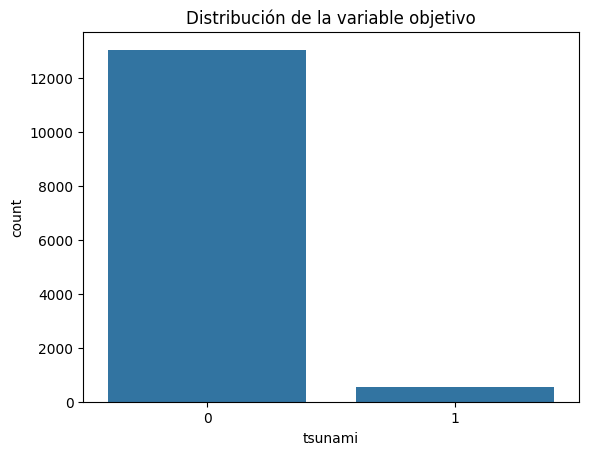

In [7]:
sns.countplot(data=df, x='tsunami')
plt.title('Distribución de la variable objetivo')
plt.show()

**96,0% clase 0 / 4,0% clase 1** — un desbalance fuerte. Si el modelo predice siempre 'no tsunami' ya acierta el 96% de las veces sin aprender nada; hay que tenerlo presente al elegir métrica (no usar solo *accuracy*) y al decidir si hace falta balanceo de clases.

In [8]:
print("=== 7. ASIMETRÍA DE LAS NUMÉRICAS ===")
print(df.select_dtypes("number").skew().sort_values())

=== 7. ASIMETRÍA DE LAS NUMÉRICAS ===
longitude       -0.537772
latitude         0.068136
rms              0.487706
dist_costa_km    0.532405
gap              1.224219
nst              1.487915
mag              2.155601
dmin             2.904011
depth            4.055570
tsunami          4.695764
sig              7.659796
dtype: float64


### Histogramas de las columnas con cola larga

La asimetría dice **cuánto** se tuerce una columna; el histograma muestra **dónde** está la cola. Graficamos sólo las columnas candidatas al modelo con asimetría mayor a 1 (no `sig` ni `tsunami`, que no son features). Fila de arriba: la columna tal como está. Fila de abajo: la misma columna con `log1p` (logaritmo de 1 + x, que admite ceros), para ver si la transformación corrige la cola.

,asimetria_original,asimetria_log1p
depth,4.06,1.15
dmin,2.90,0.65
mag,2.16,1.86
nst,1.49,-0.39
gap,1.22,-0.16


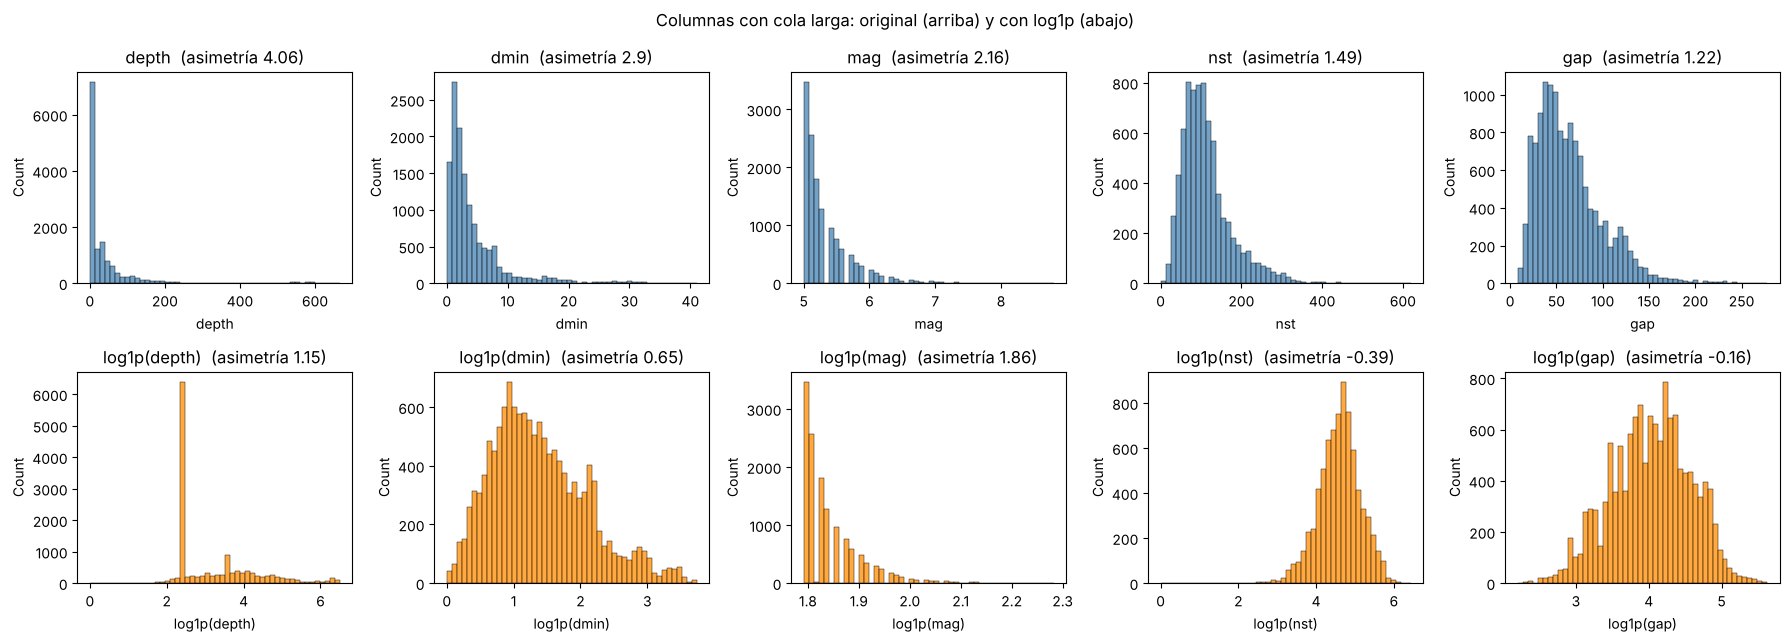

In [9]:
# Columnas candidatas al modelo con cola larga (asimetría > 1)
candidatas_num = ["mag", "depth", "dist_costa_km", "nst", "gap", "dmin", "rms"]
asimetria = df[candidatas_num].skew()
cola_larga = asimetria[asimetria > 1].sort_values(ascending=False).index.tolist()

tabla_asimetria = pd.DataFrame({
    "asimetria_original": df[cola_larga].skew(),
    "asimetria_log1p": np.log1p(df[cola_larga]).skew(),
}).round(2)
display(tabla_asimetria)

fig, axes = plt.subplots(2, len(cola_larga), figsize=(3.6 * len(cola_larga), 6.5))
for i, col in enumerate(cola_larga):
    sns.histplot(df[col].dropna(), bins=50, ax=axes[0, i], color="steelblue")
    axes[0, i].set_title(f"{col}  (asimetría {tabla_asimetria.loc[col, 'asimetria_original']})")

    sns.histplot(np.log1p(df[col]).dropna(), bins=50, ax=axes[1, i], color="darkorange")
    axes[1, i].set_title(f"log1p({col})  (asimetría {tabla_asimetria.loc[col, 'asimetria_log1p']})")
    axes[1, i].set_xlabel(f"log1p({col})")

fig.suptitle("Columnas con cola larga: original (arriba) y con log1p (abajo)")
plt.tight_layout()
plt.show()

In [10]:
# Lo que muestra el pico de depth: ¿cuántos sismos tienen exactamente 10 km?
pct_depth_10 = (df["depth"] == 10).mean() * 100
print(f"Sismos con depth exactamente igual a 10 km: {pct_depth_10:.1f}%")

Sismos con depth exactamente igual a 10 km: 46.1%


**Qué encontré:** cinco columnas candidatas tienen asimetría mayor a 1, y `log1p` no las afecta a todas igual:

- **`dmin`** (2,90 → 0,65), **`nst`** (1,49 → −0,39) y **`gap`** (1,22 → −0,16): con `log1p` la cola desaparece y la asimetría baja de 1.
- **`depth`** (4,06 → 1,15): mejora mucho pero no del todo. El histograma muestra por qué: casi la mitad de los sismos (46,1 %) tiene **exactamente 10 km**. No es un dato medido sino un **valor estructural**: cuando la red no puede calcular la profundidad de un sismo superficial, la USGS la fija en 10 km. Ninguna transformación elimina ese pico.
- **`mag`** (2,16 → 1,86): `log1p` casi no cambia nada. Esa asimetría no viene de valores extremos sino del **corte M ≥ 5 del pipeline**: el histograma arranca en 5,0 y cae, porque hay muchos más sismos chicos que grandes. Es la forma natural de la variable, no algo para corregir.

**Qué hago con eso:** para la Entrega 3, `depth`, `dmin`, `nst` y `gap` pasan con `log1p` en los modelos sensibles a la escala (regresión logística, KNN); en los árboles no hace falta, porque no dependen de la escala. `mag` entra sin transformar. Para `depth` queda una prueba para el modelado: agregar un indicador `depth == 10` (profundidad fijada por la USGS) y medir si aporta.

## **2. Definición de métricas (Semáforo)**
Cargamos las funciones de separación y semáforo provistas por la cátedra para evaluar objetivamente cada hipótesis con un número.

In [11]:
# ==========================================
# CELDA 2: FUNCIONES DE LA CÁTEDRA (SEMÁFORO)
# ==========================================
# Definición de las métricas de la cátedra para evaluar variables de forma objetiva
def separacion(x, y):
    """Distancia entre dos muestras, en desviaciones estándar."""
    x, y = x.dropna(), y.dropna()
    return abs(x.mean() - y.mean()) / np.sqrt((x.std() ** 2 + y.std() ** 2) / 2)

def eta2(numerica, categoria):
    """Proporción de la varianza de la numérica que explica la categoría."""
    g = numerica.groupby(categoria)
    m = numerica.mean()
    return (g.count() * (g.mean() - m) ** 2).sum() / ((numerica - m) ** 2).sum()

def asociacion(x, y):
    """Pearson, Spearman y la brecha entre ambos."""
    p, s = x.corr(y), x.corr(y, method="spearman")
    return pd.Series({"pearson": p, "spearman": s, "brecha": s - p}).round(3)

CORTES = {"separacion": (0.2, 0.8), "eta2": (0.05, 0.25),
          "correlacion": (0.2, 0.6), "brecha": (0.05, 0.15)}

def semaforo(valor, medida):
    """Devuelve la zona en la que cae el valor, según la medida usada."""
    bajo, alto = CORTES[medida]
    v = abs(valor)
    return "rojo" if v < bajo else "verde" if v > alto else "amarillo"

## **3. Las cuatro fichas de hipótesis**
A continuación, presentamos cuatro hipótesis que combinan conocimiento del dominio y decisiones sobre las columnas del modelo. Cada ficha cuenta con una afirmación, un resultado numérico, la zona del semáforo, un gráfico y una decisión.

### **H1 · ¿Los sismos con tsunami son más superficiales que los sin tsunami?**

**Pregunta:** ¿Conviene incluir `depth` en el modelo de tsunami? (modelado)

**Plantilla:** Comparación.

**La afirmación:** Los tsunamis son generados casi exclusivamente por sismos someros (depth < 70 km).

**Qué espero ver:** si la afirmación es cierta, la profundidad de los sismos con tsunami debería separarse claramente de la de los sismos sin tsunami (separación alta, boxplots bien distintos).

**Cómo la mido:** Comparación: separación estandarizada entre `depth` con tsunami = 1 y tsunami = 0. Boxplot de profundidad por clase.

,0
separacion,0.029
zona,rojo


Tsunamis con profundidad menor a 70 km: 84.4%


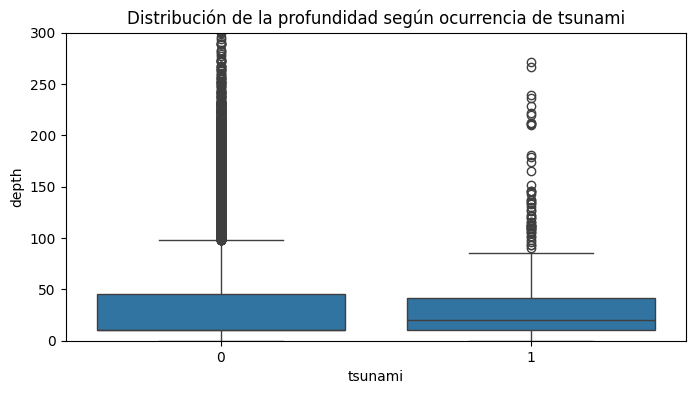

In [12]:
# H1 · Profundidad: ¿se separan las dos clases?
tsunami_si = df.loc[df["tsunami"] == 1, "depth"]
tsunami_no = df.loc[df["tsunami"] == 0, "depth"]

sep_depth = separacion(tsunami_si, tsunami_no)

display(pd.Series({"separacion": round(sep_depth, 3),
                   "zona": semaforo(sep_depth, "separacion")}))

pct_someros = (df[df['tsunami'] == 1]['depth'] < 70).mean() * 100
print(f"Tsunamis con profundidad menor a 70 km: {pct_someros:.1f}%")

plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x='tsunami', y='depth')
plt.ylim(0, 300)
plt.title("Distribución de la profundidad según ocurrencia de tsunami")
plt.show()

**Qué encontré:** la separación dio 0,029, zona **roja** (muy por debajo del corte de 0,2): la profundidad promedio es prácticamente igual entre sismos con y sin tsunami. El dato de que el 84,4 % de los tsunamis ocurre a menos de 70 km es cierto, pero no prueba separación: la gran mayoría de todos los sismos del dataset, tengan o no tsunami, también ocurre a esa profundidad, porque los sismos profundos son raros en general. La afirmación queda **refutada** como criterio para separar las clases.

**Qué movimiento hice:** ninguno sobre la población. El rojo deja una prueba pendiente para el modelado: medir el modelo con y sin `depth`, o dejar que un modelo no lineal la combine con la magnitud.

**Qué hago con eso:** `depth` pasa a la Entrega 3 como **candidata por motivo físico** (el mecanismo de generación de tsunamis sí depende de la profundidad), no por el semáforo. Se decide con el número del modelo con y sin ella.

### **H2 · ¿Todo sismo de magnitud mayor a 7,5 tiene tsunami?**

**Pregunta:** ¿Conviene incluir `mag` en el modelo, y alcanza con un umbral fijo? (modelado)

**Plantilla:** Comparación.

**La afirmación:** Cualquier sismo con magnitud extrema (mag > 7,5) siempre genera un tsunami.

**Qué espero ver:** si la magnitud separa bien en general, la separación entre clases debería caer en zona verde; si la regla absoluta es cierta, el 0 % de los sismos > 7,5 debería quedar sin tsunami.

**Cómo la mido:** Comparación: separación estandarizada entre `mag` con tsunami = 1 y tsunami = 0. Proporción de sismos > 7,5 sin tsunami. Scatter de magnitud contra distancia a la costa, coloreado por tsunami, para los sismos > 7,5.

,0
separacion,1.383
zona,verde


Sismos con mag > 7.5 sin tsunami: 21.7%


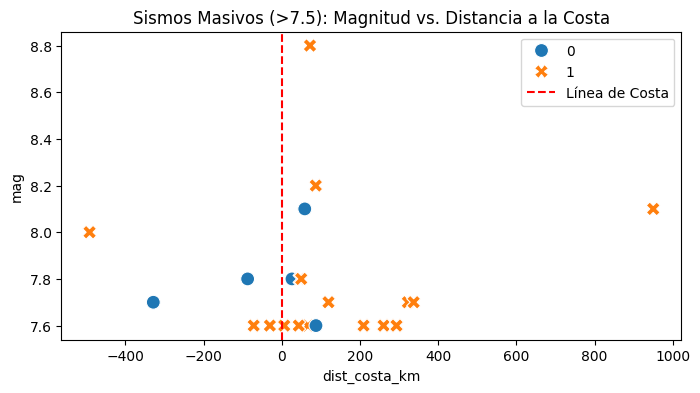

In [13]:
# H2 · Magnitud: separación general y regla del umbral 7,5
tsunami_si_mag = df.loc[df["tsunami"] == 1, "mag"]
tsunami_no_mag = df.loc[df["tsunami"] == 0, "mag"]

sep_mag = separacion(tsunami_si_mag, tsunami_no_mag)

display(pd.Series({"separacion": round(sep_mag, 3),
                   "zona": semaforo(sep_mag, "separacion")}))

sismos_masivos = df[df['mag'] > 7.5]
pct_masivos_sin_tsunami = (sismos_masivos['tsunami'] == 0).mean() * 100
print(f"Sismos con mag > 7.5 sin tsunami: {pct_masivos_sin_tsunami:.1f}%")

plt.figure(figsize=(8, 4))
sns.scatterplot(data=sismos_masivos, x='dist_costa_km', y='mag', hue='tsunami', style='tsunami', s=100)
plt.axvline(0, color='red', linestyle='--', label='Línea de Costa')
plt.title("Sismos Masivos (>7.5): Magnitud vs. Distancia a la Costa")
plt.legend()
plt.show()

**Qué encontré:** la separación general dio 1,383, zona **verde**: la magnitud distingue bien las dos clases en el dataset completo. Pero la regla absoluta es falsa: el 21,7 % de los sismos con mag > 7,5 no tiene tsunami. La afirmación queda **refutada como regla** y **confirmada como tendencia**: buena variable en general, mal umbral fijo. El gráfico muestra que esos casos no se explican solo por estar en tierra; la otra parte de la explicación queda para el modelado.

**Qué movimiento hice:** ninguno de semáforo (ya cayó en verde). El movimiento fue conceptual: en vez de una regla binaria, buscar una segunda variable (`dist_costa_km`) que explique las excepciones dentro de los sismos masivos.

**Qué hago con eso:** `mag` entra al modelo, no como umbral fijo sino combinada con otras columnas (ubicación, profundidad), o dejando que un modelo no lineal arme esa combinación.

### **H3 · ¿`sig` existe al momento de predecir, o se construye con la respuesta?**

**Pregunta:** ¿Qué columnas se pueden usar sin fuga de información? (modelado)

**Plantilla:** Comparación.

**La afirmación:** La variable `sig` (significancia) se calcula con información que no existe al momento del sismo.

**Qué espero ver:** si hay fuga, `sig` debería separar las clases mucho mejor que cualquier variable «legítima», sin una razón física que lo explique del todo; y la documentación de la USGS debería mostrar que su fórmula usa algo posterior al sismo.

**Cómo la mido:** Comparación: separación estandarizada entre `sig` con tsunami = 1 y tsunami = 0, densidad (KDE) de `sig` por clase, y lectura de cómo la USGS construye la columna.

,0
separacion,1.033
zona,verde


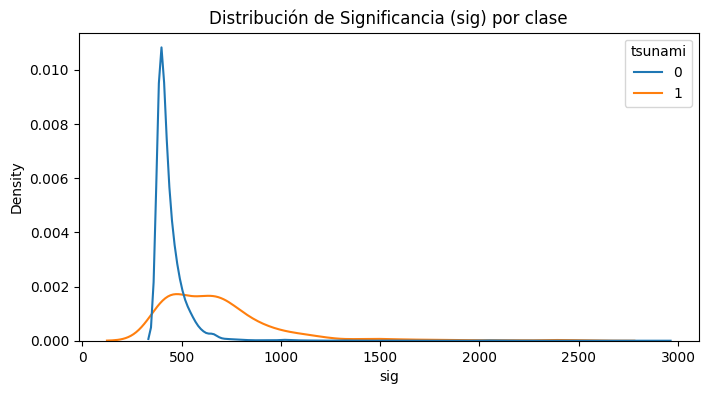

In [14]:
# H3 · sig: ¿cuánto separa?
tsunami_si_sig = df.loc[df["tsunami"] == 1, "sig"]
tsunami_no_sig = df.loc[df["tsunami"] == 0, "sig"]

sep_sig = separacion(tsunami_si_sig, tsunami_no_sig)

display(pd.Series({"separacion": round(sep_sig, 3),
                   "zona": semaforo(sep_sig, "separacion")}))

plt.figure(figsize=(8, 4))
sns.kdeplot(data=df, x='sig', hue='tsunami', common_norm=False)
plt.title("Distribución de Significancia (sig) por clase")
plt.show()

**Qué encontré:** la separación dio 1,033, zona **verde**: la segunda más alta de las variables numéricas evaluadas. Eso por sí solo no prueba fuga; lo que la confirma es la documentación de la USGS: la fórmula de `sig` incorpora si se emitió la alerta de tsunami, es decir, usa el resultado que se quiere predecir para construir el predictor. La afirmación queda **confirmada**, pero por algo que el número solo no puede mostrar.

**Qué movimiento hice:** ninguno de semáforo. El movimiento fue metodológico: no alcanza con mirar el número (que tentaría a incluirla por dar verde), hay que revisar cómo se construye la columna antes de confiar en el semáforo.

**Qué hago con eso:** `sig` sale del modelo por fuga de información, aunque tenga uno de los mejores números de las cuatro fichas.

### **H4 · ¿Importa cuán lejos de la costa está el sismo, o solo si está en el mar?**

**Pregunta:** ¿Conviene incluir `dist_costa_km`, y en qué forma: como distancia continua o sólo como tierra / mar? (modelado)

**Plantilla:** Comparación entre dos grupos, con un movimiento.

**La afirmación:** Los sismos tsunamigénicos ocurren mar adentro, por lo que su distancia a la costa (`dist_costa_km`) diferirá sustancialmente de la de los sismos sin tsunami (que incluyen eventos continentales).

**Qué espero ver:** una separación al menos amarilla ($d > 0.2$), ya que los tsunamis exigen que el epicentro esté en el océano (valores positivos de la variable) o muy cerca de la costa.

**Cómo la mido:** separación estandarizada de `dist_costa_km` entre tsunami = 1 y tsunami = 0, primero en todos los sismos y después sólo en los sismos en el mar.

In [15]:
dist_si = df.loc[df["tsunami"] == 1, "dist_costa_km"]
dist_no = df.loc[df["tsunami"] == 0, "dist_costa_km"]

sep_dist = separacion(dist_si, dist_no)
display(pd.Series({"separación original": round(sep_dist, 3),
                   "zona": semaforo(sep_dist, "separacion")}))

,0
separación original,0.172
zona,rojo


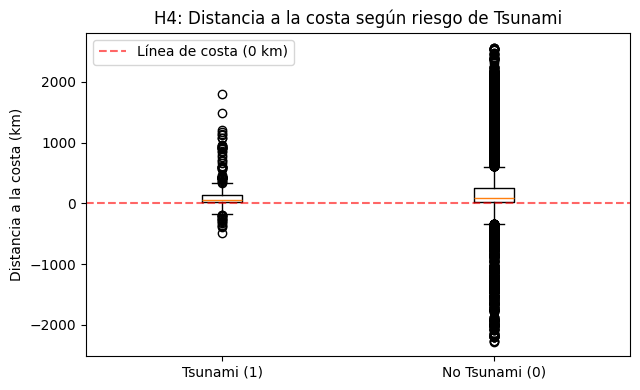

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6.5, 4))

# Creamos el boxplot pasándole las variables que ya calculaste
plt.boxplot([dist_si, dist_no], tick_labels=["Tsunami (1)", "No Tsunami (0)"])

plt.title("H4: Distancia a la costa según riesgo de Tsunami")
plt.ylabel("Distancia a la costa (km)")

# Agregamos una línea en el kilómetro 0 para identificar el límite tierra/mar
plt.axhline(0, color='red', linestyle='--', alpha=0.6, label='Línea de costa (0 km)')
plt.legend()

plt.tight_layout()
plt.show()

**Qué encontré:** sobre todos los sismos, la separación da zona **roja** (0,17): la distancia promedio a la costa de los sismos con tsunami no se diferencia mucho de la de los sismos sin tsunami. Mirando los datos, la mayoría de los sismos de las dos clases ocurre en el mar, y la variable tiene un rango muy amplio (miles de km hacia los dos lados) que diluye la diferencia.

**Qué movimiento hice:** filtro de población. Si el sismo ya ocurrió en el océano (`dist_costa_km > 0`), ¿sigue siendo relevante cuántos kilómetros mar adentro fue? Restrinjo el cálculo a los sismos en el mar para ver si la distancia fina importa.

In [17]:
# Movimiento 1: Aislar solo sismos oceánicos
df_mar = df[df["dist_costa_km"] > 0]
dist_si_mar = df_mar.loc[df_mar["tsunami"] == 1, "dist_costa_km"]
dist_no_mar = df_mar.loc[df_mar["tsunami"] == 0, "dist_costa_km"]

sep_mar = separacion(dist_si_mar, dist_no_mar)
display(pd.Series({"separación oceánica": round(sep_mar, 3),
                   "zona nueva": semaforo(sep_mar, "separacion")}))



,0
separación oceánica,0.419
zona nueva,amarillo


**Qué encontré después del movimiento:** al quedarnos sólo con los sismos en el mar, la separación **sube** de 0,17 (roja) a 0,42 (amarilla). Dentro del mar, la distancia a la costa sí distingue algo entre las clases. La afirmación queda **refutada para la población completa** y **parcialmente confirmada dentro del mar**.

**Qué hago con eso:** quedan dos formas de usar la columna en el modelo: la distancia continua o sólo el signo (`es_oceanico`: mar o tierra). El semáforo no alcanza para elegir entre las dos; se decide en el modelado midiendo el modelo con cada una.

## **4. Matriz de correlación**

**Pregunta:** ¿hay columnas candidatas que repiten la misma información entre sí (redundancia), y alguna que esté sospechosamente pegada al objetivo?

**Cómo la mido:** correlación de Pearson entre todas las columnas numéricas, con los cortes de la cátedra para correlación (0,2 / 0,6). Para los pares que se destacan, usamos `asociacion` (Pearson, Spearman y la brecha), porque varias columnas tienen cola larga y Pearson sólo mide relación lineal.

**Ojo con `tsunami`:** es binaria, así que su correlación con una numérica sólo mide si una clase tiene valores más altos que la otra en línea recta. Para decidir si una columna separa las clases ya usamos `separacion` en las fichas; acá la fila de `tsunami` sirve como control.

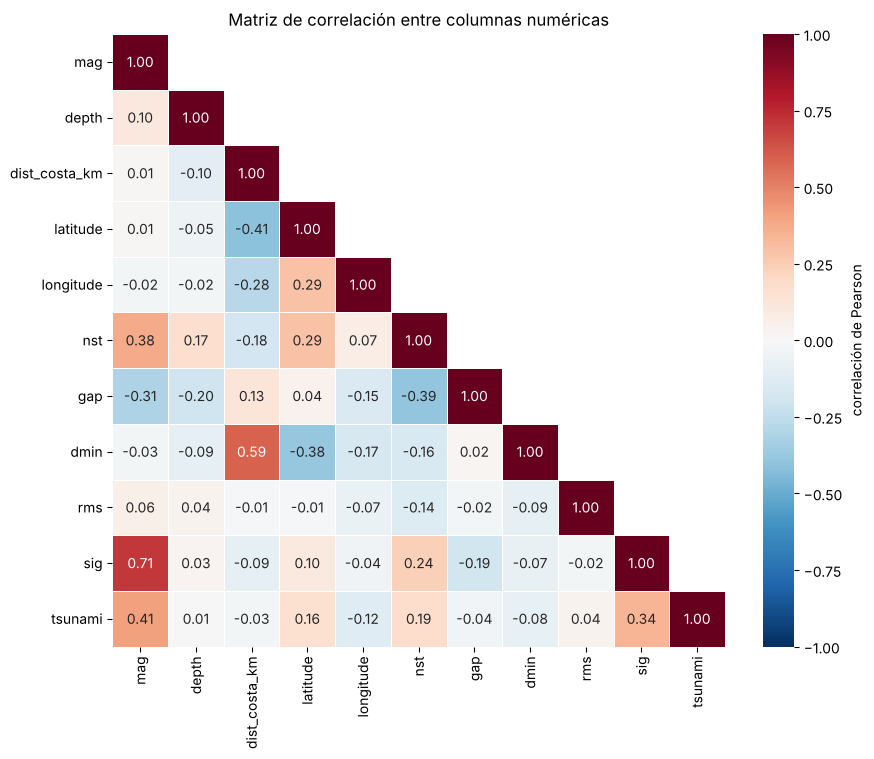

In [18]:
# Matriz de correlación (Pearson) entre las columnas numéricas
cols_corr = ["mag", "depth", "dist_costa_km", "latitude", "longitude",
             "nst", "gap", "dmin", "rms", "sig", "tsunami"]
corr = df[cols_corr].corr()

# Se oculta el triángulo superior porque repite el inferior
mascara = np.triu(np.ones_like(corr, dtype=bool), k=1)

plt.figure(figsize=(9, 7.5))
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, center=0, square=True, linewidths=0.5,
            cbar_kws={"label": "correlación de Pearson"})
plt.title("Matriz de correlación entre columnas numéricas")
plt.tight_layout()
plt.show()

In [19]:
# Pares que superan el corte rojo (|r| >= 0.2), ordenados de mayor a menor
pares = corr.where(np.tril(np.ones(corr.shape, dtype=bool), k=-1)).stack().dropna()
pares = pares.reindex(pares.abs().sort_values(ascending=False).index)

tabla_pares = pd.DataFrame({"pearson": pares.round(3),
                            "zona": [semaforo(r, "correlacion") for r in pares]})
tabla_pares[tabla_pares["zona"] != "rojo"]

,,pearson,zona
sig,mag,0.709,verde
dmin,dist_costa_km,0.587,amarillo
latitude,dist_costa_km,-0.412,amarillo
tsunami,mag,0.409,amarillo
gap,nst,-0.392,amarillo
dmin,latitude,-0.383,amarillo
nst,mag,0.380,amarillo
tsunami,sig,0.341,amarillo
gap,mag,-0.307,amarillo
nst,latitude,0.291,amarillo


In [20]:
# Pares clave: Pearson, Spearman y brecha (función de la cátedra)
pares_clave = [("mag", "sig"), ("dist_costa_km", "dmin"), ("nst", "gap"),
               ("mag", "nst"), ("depth", "dist_costa_km")]

tabla_asoc = pd.DataFrame({f"{a} – {b}": asociacion(df[a], df[b]) for a, b in pares_clave}).T
tabla_asoc["zona_spearman"] = tabla_asoc["spearman"].apply(lambda v: semaforo(v, "correlacion"))
tabla_asoc["zona_brecha"] = tabla_asoc["brecha"].apply(lambda v: semaforo(v, "brecha"))
tabla_asoc

,pearson,spearman,brecha,zona_spearman,zona_brecha
mag – sig,0.709,0.970,0.261,verde,verde
dist_costa_km – dmin,0.587,0.470,-0.117,amarillo,amarillo
nst – gap,-0.392,-0.466,-0.073,amarillo,amarillo
mag – nst,0.380,0.358,-0.022,amarillo,rojo
depth – dist_costa_km,-0.104,-0.297,-0.193,amarillo,verde


**Qué encontré:**

- **`mag` – `sig`:** Pearson 0,71 (verde) y Spearman **0,97**, brecha 0,26 (verde): `sig` es casi una función monótona de la magnitud. Lo poco que le agrega a `mag` es, justamente, la alerta de tsunami. Refuerza la decisión de H3: `sig` no trae información física nueva, sólo la respuesta.
- **`dist_costa_km` – `dmin`:** Pearson 0,59, amarillo y casi verde. Tiene sentido: `dmin` es la distancia a la estación sismológica más cercana, y las estaciones están en tierra, así que cuanto más mar adentro, más lejos queda la estación. Las dos columnas cuentan en buena parte lo mismo.
- **`mag` – `nst`** (0,38) y **`nst` – `gap`** (−0,39), ambas amarillas: las métricas de instrumentación dependen de la magnitud (un sismo más grande lo registran más estaciones y deja menos hueco de cobertura). Son en parte un reflejo de `mag`.
- **`depth` – `dist_costa_km`:** Pearson −0,10 (rojo) pero Spearman −0,30; la brecha (−0,20) cae en verde: hay relación (los sismos profundos tienden a estar más cerca de la costa o en tierra), pero no es lineal.
- **Fila de `tsunami`:** ninguna columna candidata pasa de 0,6 con el objetivo; la más alta es `mag` (0,41, amarilla), igual que en las fichas. `depth` da 0,01, consistente con el rojo de H1. Y `sig` da 0,34: por correlación **no** parece fuga, lo que muestra que la fuga se detecta leyendo cómo se construye la columna, no con este número.

**Qué hago con eso:** ningún par de columnas candidatas pasa el corte de 0,6, así que no se descarta nada por redundancia. `dmin` es la más redundante (con `dist_costa_km`): se prueba el modelo con y sin ella. Al leer la importancia de las variables en la Entrega 3, hay que tener en cuenta que `mag`, `nst` y `gap` comparten información: si una de ellas sale del modelo, las otras pueden «absorber» su peso.

## **5. La tabla de columnas candidatas**

Esta tabla define qué variables pasan a la etapa de modelado y responde a la pregunta más importante del chequeo de fuga: **¿existiría al predecir?** La columna «Zona» es la del semáforo de separación; donde dice «—», la columna no se midió con el semáforo.

| Columna | Qué mide | Zona | Decisión | ¿Existiría al predecir? |
| :--- | :--- | :--- | :--- | :--- |
| **tsunami** | Si la USGS marcó el evento con alerta de tsunami. | — | **Objetivo** | — |
| **mag** | Magnitud del sismo. | Verde (1,38) | Entra sin transformar (su asimetría viene del corte M ≥ 5) | Sí, se calcula en los primeros minutos. |
| **depth** | Profundidad del hipocentro. | Roja (0,03) | Entra como candidata por motivo físico, con `log1p`; se mide con y sin ella, y con un indicador `depth == 10` | Sí, se triangula rápidamente. |
| **dist_costa_km** | Distancia Haversine a la costa (negativa = tierra). | Roja (0,17); amarilla sólo en el mar (0,42) | Entra; continua o binaria (`es_oceanico`) se decide midiendo | Sí, se calcula geométricamente al instante. |
| **latitude / longitude** | Coordenadas del epicentro. | — | Entran | Sí. |
| **magType** | Escala usada para medir la magnitud. | — | Entra con One-Hot Encoding | Sí. |
| **nst / dmin** | Cantidad de estaciones y distancia a la estación más cercana. | — | Candidatas, con `log1p`; se prueban con y sin cada una (`dmin` es redundante con `dist_costa_km`, r = 0,59) | Dudoso: la USGS las recalcula al revisar el evento. |
| **gap / rms** | Métricas de error de triangulación. | Roja | Candidatas débiles (`gap` con `log1p`); se prueban con y sin cada una | Dudoso: la USGS las recalcula al revisar el evento. |
| **time** | Fecha y hora del sismo. | — | Sale como predictor; se usa para armar la partición | Sí, pero no es predictor físico. |
| **sig** | Índice de significancia de la USGS. | Verde (1,03) | Sale (fuga de información; además Spearman 0,97 con `mag`) | **No.** Incluye la alerta de tsunami. |
| **status / type / net** | Estado de revisión, tipo de evento y red. | — | Salen (constantes o casi) | Sí, pero no varían. |
| **id / place** | Identificador y descripción textual del lugar. | — | Salen (identificadores) | Sí, pero no aportan como predictores. |